In [1]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
insurance_data = pd.read_csv("insurance.csv")

In [3]:
X = insurance_data.drop(columns=["charges"])
y = insurance_data["charges"]

In [4]:
X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"female": 1, "male": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

In [5]:
X["age_smoker"] = X["age"] * X["smoker"]
X["bmi_smoker"] = X["bmi"] * X["smoker"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
alphas = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]

mses = []

for a in alphas:

    ridge_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=a)
    )

    ridge_model.fit(X_train, y_train)

    y_pred = ridge_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)

    print(f"MSE for alpha={a}: ", mse)

    mses.append(mse)

MSE for alpha=0.001:  20922516.62347345
MSE for alpha=0.1:  20913705.08245916
MSE for alpha=1:  20852664.412691418
MSE for alpha=2:  20818872.432424914
MSE for alpha=5:  20862051.34745233
MSE for alpha=10:  21174845.486321416
MSE for alpha=20:  22011290.55849635
MSE for alpha=30:  22798368.67236428
MSE for alpha=40:  23477326.065094534
MSE for alpha=50:  24060593.55982864
MSE for alpha=100:  26097700.110192303


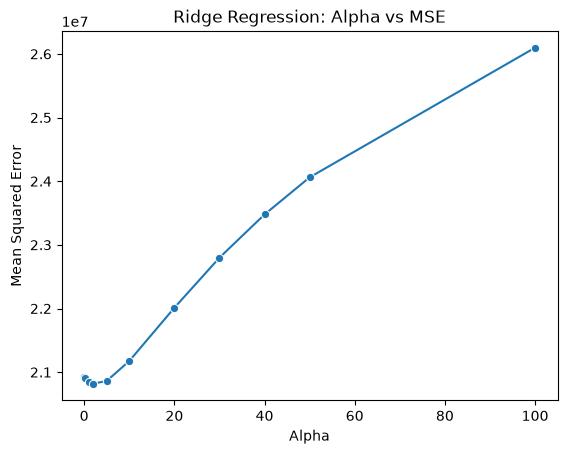

In [8]:
sns.lineplot(x=alphas, y=mses, marker="o")

plt.xlabel("Alpha")
plt.ylabel("Mean Squared Error")
plt.title("Ridge Regression: Alpha vs MSE")
plt.show()

In [9]:
ridge_cv_model = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=alphas,
        cv=5
    )
)

ridge_cv_model.fit(X_train, y_train)

print("Best alpha:", ridge_cv_model.named_steps["ridgecv"].alpha_)

Best alpha: 0.001


In [10]:
y_pred = ridge_cv_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE =", mse)
print("R2 Score =", r2)

MSE = 20922516.62347345
R2 Score = 0.8652322861357349
